# Topic Analysis - Research Document Mining
Search engines index thousands of new research publications each year, making it increasingly challenging for researchers
and analysts to identify emerging trends and monitor the evolution of research topics. To address this challenge, you have
been tasked with designing a prototype system for tracking research trends in the field of artificial intelligence. As a proof of
concept, the system will apply topic modelling techniques to a small collection of recent AI research articles provided in the
research_corpus.zip dataset, with the aim of uncovering the main themes and research directions represented in the corpus.


In [150]:
# load libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from matplotlib.pylab import matrix
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity

In [151]:
# load data
path = Path("../data")

files = sorted(path.glob("research_[1-5].txt"))

corpus = pd.DataFrame([
    {
        "article_id": file.stem,
        "content": file.read_text(encoding="utf-8-sig")
    }
    for file in files
])

In [152]:
# inspect data
corpus["word_count"] = corpus["content"].str.split().str.len()
corpus["character_count"] = corpus["content"].str.len()

print(corpus[["article_id", "word_count", "character_count"]].to_string(index=False))

article_id  word_count  character_count
research_1        5602            38160
research_2        2416            16104
research_3        3828            26154
research_4        5922            38950
research_5        4027            26831


### Denoising decisions
URLs, email addresses, invisible characters, standalone page numbers and reference sections are removed where identifiable. Scientific punctuation and Unicode letters are preserved to avoid losing meaningful terminology. For summarisation, stopword removal and stemming are not applied to the original sentences because they can damage readability; TF-IDF handles stopwords at the feature-extraction stage. The cleaned texts are checked for empty documents and compared with their original lengths. PDF extraction artefacts are heterogeneous, so some may require document-specific review.

In [153]:

# preprocess text
def clean_article(text):
    text = str(text)

    # remove exact duplicated article content
    midpoint = len(text) // 2

    if (
        len(text) % 2 == 0
        and text[:midpoint] == text[midpoint:]
    ):
        text = text[:midpoint]

    # remove website navigation content
    text = re.sub(
        r"(?is)\bSimilar content being viewed by others\b"
        r".*?(?=\bIntroduction\b)",
        " ",
        text,
        count=1
    )

    # remove known journal and page artefacts
    text = re.sub(
        r"(?i)\bEducational Researcher,\s*Vol\.\s*33,"
        r"\s*No\.\s*7,\s*pp\.\s*14[–-]26\s*"
        r"OCTOBER\s+2004\s+15\b",
        " ",
        text
    )

    text = re.sub(
        r"(?i)\b16\s+EDUCATIONAL RESEARCHER\b",
        " ",
        text
    )

    # remove URLs, emails and invisible characters
    text = re.sub(
        r"https?://\S+|www\.\S+|\S+@\S+",
        " ",
        text
    )
    text = re.sub(r"[\u200b-\u200d\ufeff]", "", text)

    # remove standalone page numbers
    text = re.sub(r"(?m)^\s*\d{1,3}\s*$", " ", text)

    # remove references section
    text = re.split(
        r"(?im)^\s*(?:references|bibliography)\s*$",
        text,
        maxsplit=1
    )[0]

    # remove metadata lines
    text = re.sub(
        r"(?im)^\s*(?:keywords?|corresponding author)\s*:?.*$",
        " ",
        text
    )
    
    # remove confirmed section-heading artefacts
    text = text.replace(
    "The Use of Cronbach’s Alpha in Science Education Studies",
    " "
    )
    
    text = text.replace(
    "The Frequency of Use of Cronbach’s Alpha in Science Education",
    " "
    )
    
    # normalise whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


corpus["cleaned_content"] = corpus["content"].map(clean_article)

# validate preprocessing
corpus["cleaned_word_count"] = (
    corpus["cleaned_content"].str.split().str.len()
)

corpus["words_removed"] = (
    corpus["word_count"] - corpus["cleaned_word_count"]
)

print(
    corpus[
        [
            "article_id",
            "word_count",
            "cleaned_word_count",
            "words_removed"
        ]
    ].to_string(index=False)
)

print(
    "\nEmpty documents:",
    corpus["cleaned_content"].str.strip().eq("").sum()
)

print(
    "Duplicate documents:",
    corpus["cleaned_content"].duplicated().sum()
)

# save cleaned corpus
output_path = Path(
    "../data/processed/cleaned_research_corpus.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

corpus.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

article_id  word_count  cleaned_word_count  words_removed
research_1        5602                2787           2815
research_2        2416                2406             10
research_3        3828                3828              0
research_4        5922                5854             68
research_5        4027                4019              8

Empty documents: 0
Duplicate documents: 0


### Text Preprocessing and Denoising

The research articles were preprocessed to reduce irrelevant information introduced during document extraction. The cleaning procedure removed URLs, email addresses, invisible Unicode characters, standalone page numbers, identifiable metadata lines, and reference sections.

Whitespace was normalised while preserving the original wording and sentence structure for extractive summarisation. Stopword removal was deferred to TF-IDF vectorisation to maintain the readability of the source sentences.

Preprocessing was evaluated by comparing word counts before and after cleaning and checking for empty or duplicate documents.

In [154]:
# inspect remaining document artefacts
patterns = {
    "journal_header": r"(?i)educational researcher",
    "page_header": r"(?im)^\s*\d+\s+[A-Z][A-Z\s]+\d*\s*$",
    "email": r"\b[\w.+-]+@[\w.-]+\.\w+\b",
    "url": r"https?://\S+|www\.\S+",
    "related_content": r"(?i)similar content being viewed by others",
    "correspondence": r"(?i)corresponding author",
    "references": r"(?im)^\s*references\s*$"
}

for _, article in corpus.iterrows():
    text = article["cleaned_content"]

    print(f"\n{article['article_id']}")

    for name, pattern in patterns.items():
        matches = re.findall(pattern, text)
        print(f"{name}: {len(matches)}")



research_1
journal_header: 3
page_header: 0
email: 0
url: 0
related_content: 0
correspondence: 0
references: 0

research_2
journal_header: 0
page_header: 0
email: 0
url: 0
related_content: 0
correspondence: 0
references: 0

research_3
journal_header: 1
page_header: 0
email: 0
url: 0
related_content: 0
correspondence: 0
references: 0

research_4
journal_header: 0
page_header: 0
email: 0
url: 0
related_content: 0
correspondence: 0
references: 0

research_5
journal_header: 0
page_header: 0
email: 0
url: 0
related_content: 0
correspondence: 0
references: 0


In [155]:

# inspect remaining artefacts
patterns = {
    "research_1": r"educational researcher",
    "research_3": r"educational researcher",
    "research_4": r"similar content being viewed by others"
}

for article_id, pattern in patterns.items():
    text = corpus.loc[
        corpus["article_id"] == article_id,
        "cleaned_content"
    ].iloc[0]

    print(f"\n{article_id.upper()}")

    for match in re.finditer(pattern, text, flags=re.IGNORECASE):
        start = max(0, match.start() - 90)
        end = min(len(text), match.end() + 90)

        print("...", text[start:end], "...")
        print("-" * 60)



RESEARCH_1
... fic outcomes can be determined reliably and validly. According to this school of thought, educational researchers should eliminate their biases, remain emotionally detached and uninvolved with the objec ...
------------------------------------------------------------
... en qualitative and quantitative research (which have been frequently written about in the Educational Researcher and other places), there are some similarities between the various approaches that are so ...
------------------------------------------------------------
... rists. For example, on the “positivist” side of the fence, the barriers that quantitative educational researchers have built arise from a narrow definition of the concept of “science.” 6 As noted by Onw ...
------------------------------------------------------------

RESEARCH_3
...  is 1099 1100 • RICHEY, KLEIN, NELSON often unclear, not only to the broader community of educational researchers, but to many instructional technology rese

In [156]:
# validate duplicate removal
original = corpus.loc[
    corpus["article_id"] == "research_1", "content"
].iloc[0]

cleaned = corpus.loc[
    corpus["article_id"] == "research_1", "cleaned_content"
].iloc[0]

phrase = (
    "According to this school of thought, "
    "educational researchers should eliminate their biases"
)

original_matches = re.findall(
    re.escape(phrase),
    re.sub(r"\s+", " ", original),
    flags=re.IGNORECASE
)

cleaned_matches = re.findall(
    re.escape(phrase),
    re.sub(r"\s+", " ", cleaned),
    flags=re.IGNORECASE
)

print("Original characters:", len(original))
print("Cleaned characters:", len(cleaned))
print("Original phrase occurrences:", len(original_matches))
print("Cleaned phrase occurrences:", len(cleaned_matches))

Original characters: 38160
Cleaned characters: 18987
Original phrase occurrences: 2
Cleaned phrase occurrences: 1



### Preprocessing Validation

I examined the cleaned articles for remaining extraction artefacts and inspected the surrounding text of the identified matches.

The inspection showed that some occurrences of `educational researcher` were legitimate references within the research discussion. However, `research_1` also contained journal publication information and a page header embedded within sentences.

I updated the preprocessing function to remove these identifiable artefacts without deleting meaningful references to educational researchers.

In `research_4`, I identified website-related content listing other publications. I removed this section because it was unrelated to the article's discussion of Cronbach's alpha.

The inspection identified an exact duplication in research_1. I removed the duplicated half during preprocessing and verified that the repeated phrase occurred once in the cleaned article rather than twice in the original.

These corrections aim to improve the quality of the text used for summarisation while preserving the original research content.

FIRST ARTICLE SUMMARY:
 Further, they contend that the observer is separate from the entities that are subject to observation.
Qualitative purists (also called constructivists and interpretivists) reject what they call positivism.
We will try to clarify the most important issues in the remainder of this article.
For example, qualitative researchers should be free to use quantitative methods, and quantitative researchers should be free to use qualitative methods.
There are several interesting myths that appear to be held by some purists.


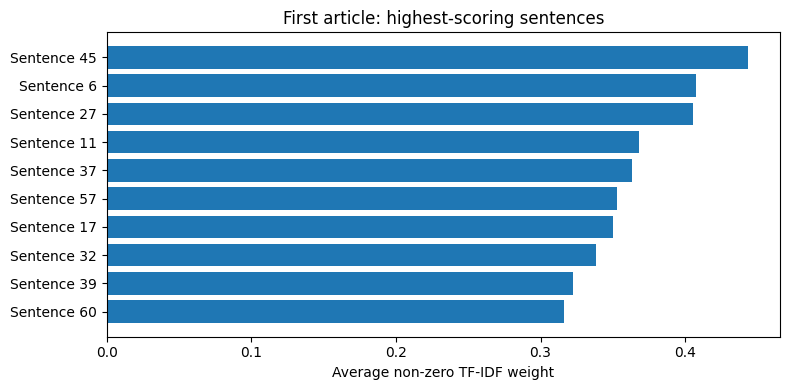

In [157]:
# summarise first article

def split_sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)
            if 12 <= len(s.split()) <= 65]

def extractive_summary(text, count=5):
    sentences = split_sentences(text)
    if not sentences:
        return [], []
    matrix = TfidfVectorizer(stop_words='english').fit_transform(sentences)
    scores = np.asarray(matrix.sum(axis=1)).ravel()
    
    # calculate average TF-IDF weight
    term_counts = np.asarray(
        (matrix > 0).sum(axis=1)
    ).ravel()

    scores = scores / np.maximum(term_counts, 1)

    selected = sorted(np.argsort(scores)[-min(count, len(sentences)):])
    return [sentences[i] for i in selected], [(i + 1, scores[i]) for i in np.argsort(scores)[-10:][::-1]]

first_summary, sentence_ranks = extractive_summary(corpus.loc[0, 'cleaned_content'])
print('FIRST ARTICLE SUMMARY:\n', '\n'.join(first_summary))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([f'Sentence {i}' for i, _ in sentence_ranks][::-1],
        [score for _, score in sentence_ranks][::-1])
ax.set_xlabel("Average non-zero TF-IDF weight")
ax.set_title('First article: highest-scoring sentences')
plt.tight_layout()
plt.show()

### Individual Summarisation Interpretation

The first research article was summarised using TF-IDF-based extractive summarisation. The five highest-scoring sentences were selected and arranged in their original document order.

The visualisation illustrates the ten highest sentence scores, highlighting sentences containing terms that receive greater TF-IDF weight.

Averaging non-zero TF-IDF weights reduces the influence of sentence length compared with summing the weights. However, this does not guarantee that the selected sentences represent the article's main argument or form a coherent summary.

Additionally, TF-IDF evaluates lexical importance rather than semantic understanding, meaning that highly ranked sentences may not always provide the most coherent or comprehensive summary.

### Aggregate Document Summarisation

The remaining four research articles were analysed using centroid-based extractive summarisation. Unlike the first article, which was summarised using individual sentence TF-IDF scores, this approach uses cosine similarity to identify sentences that are representative of the combined document collection.

Sentences were filtered to reduce the inclusion of metadata, incomplete fragments and citation-heavy passages. TF-IDF vectors were generated across the remaining articles, and a shared corpus centroid was calculated.

The two highest-ranked valid sentences from each article were selected to provide coverage across the collection. Their average cosine similarity scores were visualised to compare how closely the selected sentences aligned with the central vocabulary of the corpus.

AGGREGATE SUMMARY:

research_2:
- Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions (Bradbury-Jones, 2007; Guillemin and Gillam, 2004).
- Thus, it enhances the quality of the research by allowing researchers to ponder the ways in which who they are may both assist and hinder the process of co-constructing meanings (Lietz et al., 2006), frees them to handle and present the data better, and consider its complex meanings and contribution to the understanding of social phenomena and of the process involved in knowledge production.

research_3:
- This blend is most obvious in developmental research, those studies that involve the production of knowledge with the ultimate aim of improving the processes of instructional design, development, and evaluation.
- While instructional development typically builds on previous research, developmental research attempts to produ

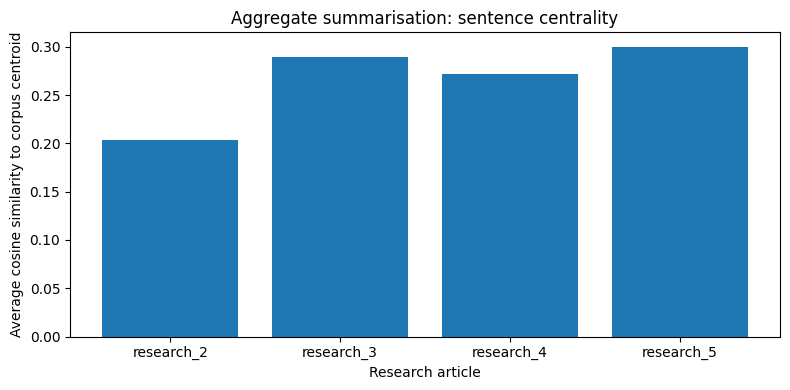

In [158]:
# summarise remaining articles

def valid_sentence(sentence):
    words = sentence.split()
    lower = sentence.lower()

    if not 12 <= len(words) <= 65:
        return False

    excluded = [
        "keywords:",
        "corresponding author",
        "doi:",
        "copyright",
        "all rights reserved",
        "university press",
        "http",
        "www.",
        "social change Introduction",
        "Denzin’s Paradigm Shift: Triangulation in Qualitative Research"
    ]

    if any(term.lower() in lower for term in excluded):
        return False

    # exclude citation-heavy sentences
    citations = re.findall(r"\([^)]*\d{4}[^)]*\)", sentence)

    if len(citations) > 2:
        return False

    # exclude fragments without sentence punctuation
    if not sentence.endswith((".", "!", "?")):
        return False
    # exclude incomplete citation fragments
    if re.search(r"\(\s*[A-Z]\.\s*$", sentence):
        return False

    return True


# prepare sentences
remaining = corpus.iloc[1:].copy()

rows = [
    (article_id, sentence)
    for article_id, text in zip(
        remaining["article_id"],
        remaining["cleaned_content"]
    )
    for sentence in split_sentences(text)
    if valid_sentence(sentence)
]

sentence_df = pd.DataFrame(
    rows,
    columns=["article_id", "sentence"]
)

if sentence_df.empty:
    raise ValueError("No valid sentences available for summarisation.")

# calculate sentence similarity
vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=2
)

sentence_matrix = vectorizer.fit_transform(
    sentence_df["sentence"]
)

centroid = np.asarray(sentence_matrix.mean(axis=0))

sentence_df["centrality"] = cosine_similarity(
    sentence_matrix,
    centroid
).ravel()

# select two sentences per article
aggregate_summary = (
    sentence_df
    .sort_values("centrality", ascending=False)
    .groupby("article_id", group_keys=False)
    .head(2)
    .sort_values("article_id")
)

# display aggregate summary
print("AGGREGATE SUMMARY:\n")

for article_id, group in aggregate_summary.groupby("article_id"):
    print(f"{article_id}:")

    for sentence in group["sentence"]:
        print(f"- {sentence}")

    print()

# visualise average centrality
summary_scores = (
    aggregate_summary
    .groupby("article_id")["centrality"]
    .mean()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(summary_scores.index, summary_scores.values)
ax.set_xlabel("Research article")
ax.set_ylabel("Average cosine similarity to corpus centroid")
ax.set_title("Aggregate summarisation: sentence centrality")

plt.tight_layout()
plt.show()

### Aggregate Summarisation Interpretation

The aggregate summarisation approach identified representative sentences from the remaining four research articles using TF-IDF and cosine similarity.

The articles address different aspects of research methodology, including researcher reflexivity, developmental research, measurement reliability and triangulation. 

The visualisation compares the average cosine similarity scores of the selected sentences across the articles. Higher scores indicate stronger lexical similarity to the combined corpus centroid.